# 08 – The 3D shape of the proton shower: a body of revolution cut by the detector planes

## 1. Introduction

Notebooks 01–06 describe the proton shower as a **body of revolution** around the direction of incidence: a density
$\rho(z', r \mid p)$ on the $(z', r)$ grid. This notebook asks whether a better 3D shape exists, and finds three things.

1. **The measured shower is not a body of revolution.** The calorimeter layers are perpendicular to the detector axis, the proton
   arrives at an angle $\theta = 3^\circ$–$36^\circ$, and the origin of the shower frame is the first hit layer. Hence every hit satisfies
   $z_{trans} = z'\cos\theta - x'\sin\theta \ge 0$: the body of revolution is **cut by an oblique plane through the origin** (and by a second
   one at the back face). Averaged over the azimuth this gives the cone-shaped front that the networks (05, 06) learn and that a product
   $L(z')\,T(r)$ cannot represent.
2. This cut is pure geometry and **costs no parameter**: for a ring $(z', r)$ the accepted fraction of the azimuth is a closed-form
   $\arccos$ expression. It can be used in two ways: as an event-wise normalisation (the "3D likelihood"), or – averaged over the
   incidence angles – as a fixed factor $\bar A(z', r)$ that turns any formula into a better pure $(z', r \mid p)$ model in the
   report's own metric.
3. With the geometry taken out, the remaining deficit of the GFlash formula is concentrated below 2 GeV, where the proton
   (unlike the pion) mostly **stops by ionisation** instead of showering.

**Coordinates** (as in 00–06): $z'$ = depth along the direction of incidence, $r=\sqrt{x'^2+y'^2}$; in addition $x'$ is the transverse
coordinate in the plane spanned by the shower axis and the detector axis ($x' > 0$ points radially outward and upstream), $y'$ lies
in the layer plane.

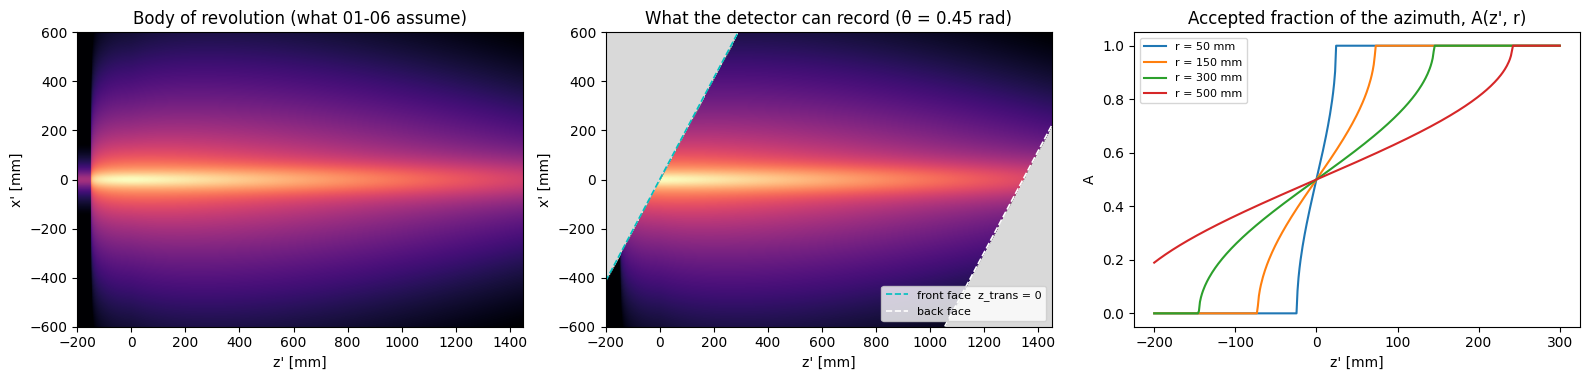

In [1]:
import numpy as np, matplotlib.pyplot as plt

# illustrative shower (the same toy as in 01-03) seen from the side: in 3D it is cut by the tilted front and back faces
LAM, Rc, Rt, pc, TH, DEPTH = 170.0, 25.0, 110.0, 0.6, 0.45, 1210.0
z, x = np.meshgrid(np.linspace(-200, 1450, 420), np.linspace(-600, 600, 301))
tmax = LAM * (0.2 * np.log(8) + 0.7); bb = 0.5 / LAM; aa = 1 + bb * tmax
s = np.clip(z + 150, 1e-3, None); rc = Rc * (1 + np.clip(z, 0, None) / 800)
rho = s ** (aa - 1) * np.exp(-bb * s) * (pc * rc**2 / (x**2 + rc**2)**2 + (1 - pc) * (4 * rc)**2 / (x**2 + (4 * rc)**2)**2)
zt = z * np.cos(TH) - x * np.sin(TH)                       # depth along the detector axis
inside = (zt >= 0) & (zt <= DEPTH)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.9))
for a_, d, t in ((ax[0], rho, "Body of revolution (what 01-06 assume)"), (ax[1], np.where(inside, rho, np.nan), "What the detector can record (θ = 0.45 rad)")):
    a_.imshow(np.log10(d), extent=[-200, 1450, -600, 600], origin="lower", aspect="auto", cmap="magma", vmin=np.log10(rho.max()) - 5, vmax=np.log10(rho.max()))
    a_.set(title=t, xlabel="z' [mm]", ylabel="x' [mm]"); a_.set_facecolor("0.85")
zz = np.linspace(-200, 1450, 10)
ax[1].plot(zz, zz / np.tan(TH), "c--", lw=1.2, label="front face  z_trans = 0"); ax[1].plot(zz, (zz * np.cos(TH) - DEPTH) / np.sin(TH), "w--", lw=1.2, label="back face")
ax[1].set_ylim(-600, 600); ax[1].legend(fontsize=8, loc="lower right")
zq = np.linspace(-200, 300, 400)
for r_ in (50, 150, 300, 500):
    ax[2].plot(zq, 1 - np.arccos(np.clip(zq / (r_ * np.tan(TH)), -1, 1)) / np.pi, label=f"r = {r_} mm")
ax[2].set(title="Accepted fraction of the azimuth, A(z', r)", xlabel="z' [mm]", ylabel="A"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Left:** the body of revolution assumed so far. **Middle:** the same shower as the detector can see it: everything in front of the
(tilted) front face and behind the back face is missing. **Right:** the fraction of the ring $(z', r)$ that lies behind the front face,
$A = 1 - \arccos\!\big(z'/(r\tan\theta)\big)/\pi$: half of every ring is lost at $z' = 0$, and rings of large radius are partly
visible already at $z' < 0$. This is the cone in the $(z', r)$ maps of the data.

## 2. Loading data

In [2]:
PARTICLES = ['proton']
DATA_DIR = "/home/user/data/simulations/regression-proton/"     # location of the CSVs
OUT_DIR = "results"                                             # models and exports go here
%run -i ./00_common.ipynb

/home/user/.venv/lib/python3.10/site-packages/nbformat/__init__.py:96: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


device: cuda | data: /home/user/data/simulations/regression-proton/ | output: results


In [3]:
# Loading the 16.7 GB CSV takes about 15 minutes; the compact tensors are therefore cached after the first run.
CACHE = "cache/proton_sets.pt"
if os.path.exists(CACHE):
    ck = torch.load(CACHE, weights_only=False)
    geo = ck["geo"]
    data = {k: Showers(v["ev"], v["off"], v["xyz"], v["w"], v["box"]).to(DEVICE) for k, v in ck["sets"].items()}
    print("loaded the cached split (identical to load_data('proton'), SEED = 1)")
else:
    df, geo, data = load_data("proton")
    os.makedirs("cache", exist_ok=True)
    torch.save({"geo": geo, "sets": {k: {"ev": {a: b.cpu() for a, b in s.ev.items()}, "off": s.off.cpu(), "xyz": s.xyz.cpu(),
                                         "w": s.w.cpu(), "box": s.box.cpu()} for k, s in data.items()}}, CACHE)
print("geometry:", geo)
for k, s in data.items():
    print(f"{k:5s}: {len(s):6d} events, {len(s.w):9d} hits, p = {float(s.ev['p'].min()):.2f}–{float(s.ev['p'].max()):.2f} GeV")
theta_tr = torch.acos(data["train"].ev["R"][:, 2, 2])
print(f"incidence angle θ: {float(theta_tr.min()):.3f}–{float(theta_tr.max()):.3f} rad, median {float(theta_tr.median()):.3f}")
display(data["train"].hits().describe().T)

loaded the cached split (identical to load_data('proton'), SEED = 1)
geometry: {'layer': 20.5, 'cell': 48.59999999999991, 'z_back': 4882.15}
train:  69946 events,  20545647 hits, p = 0.29–20.00 GeV
val  :  14987 events,   4411185 hits, p = 0.33–20.00 GeV
test :  14992 events,   4412396 hits, p = 0.25–20.00 GeV
incidence angle θ: 0.052–0.628 rad, median 0.444


,count,mean,std,min,25%,50%,75%,max
z,20545647.0,423.473511,295.923615,-1.999876e+02,191.088272,370.840546,609.841248,1449.919067
r,20545647.0,190.130692,141.344269,0.000000e+00,84.936764,152.768555,257.986649,699.999634
w,20545647.0,0.003404,0.016212,1.500384e-12,0.000069,0.000217,0.001653,1.000000
p,20545647.0,13.163937,4.689392,2.853453e-01,9.745512,13.847186,17.156998,19.999752
ev,20545647.0,33781.951407,19547.055801,0.000000e+00,16818.000000,33720.000000,50697.000000,69945.000000


## 3. Geometry: the detector slab in the shower frame

The shower frame is obtained from the detector frame by a translation to the origin (the energy-weighted centroid of the hits in the
first hit layer, $z_0 = \min z$ of the event) and the rotation $R$ whose rows are $e_\theta$, $e_\varphi$, $e_r$ (`rotation` in 00).
Inverting it, the depth of a point **along the detector axis** is

$$z_{trans} = z'\cos\theta - x'\sin\theta .$$

By construction no hit can have $z_{trans} < 0$, and the last layer ends at $D = z_{back} - z_0$. With the half layer thickness $h$
of the cell boxes, every recorded deposit lies in the **slab**

$$-h \;\le\; z'\cos\theta - x'\sin\theta \;\le\; D .$$

In cylindrical coordinates around the shower axis, $x' = r\cos\phi$, so a ring $(z', r)$ is inside the slab for
$\cos\phi \in \big[\tfrac{z'\cos\theta - D}{r\sin\theta},\; \tfrac{z'\cos\theta + h}{r\sin\theta}\big]$ and the accepted fraction of its azimuth is

$$A_\theta(z', r) = \frac{1}{\pi}\Big[\arccos\big(\mathrm{clip}(\ell)\big) - \arccos\big(\mathrm{clip}(u)\big)\Big],\qquad
\ell = \frac{z'\cos\theta - D}{r\sin\theta},\quad u = \frac{z'\cos\theta + h}{r\sin\theta},$$

with both arguments clipped to $[-1, 1]$. There is **no free parameter**: $\theta$ and $D$ are known for every event (they are already
used by the likelihood of 00 for the rotated cell box and for the back-face distance $z_b = D/\cos\theta$).

In [4]:
def slab_accept(cos_t, sin_t, D, half, nsub=2, front=True, back=True):
    """Azimuthal acceptance A (B, N_Z, N_R): fraction of every (z', r) ring inside the detector slab of each event.
    Each grid cell is sampled at nsub x nsub points (equal-area in r)."""
    k = (torch.arange(nsub, device=cos_t.device, dtype=torch.float32) + 0.5) / nsub
    zs = Z_EDGES[:-1, None] + DZ * k                                                                      # (N_Z, nsub)
    rs = torch.sqrt(R_EDGES[:-1, None] ** 2 + (R_EDGES[1:, None] ** 2 - R_EDGES[:-1, None] ** 2) * k)     # (N_R, nsub)
    zc = zs[None, :, :, None, None] * cos_t[:, None, None, None, None]
    den = (rs[None, None, None, :, :] * sin_t[:, None, None, None, None]).clamp_min(1e-9)
    lo = ((zc - D[:, None, None, None, None]) / den).clamp(-1, 1) if back else -torch.ones_like(zc / den)
    hi = ((zc + half) / den).clamp(-1, 1) if front else torch.ones_like(zc / den)
    return ((torch.acos(lo) - torch.acos(hi)) / math.pi).mean((2, 4))


def event_slab(b, box, nsub=2, front=True, back=True):
    cos_t = b.R[:, 2, 2]
    sin_t = torch.sqrt((1 - cos_t ** 2).clamp_min(0))
    return slab_accept(cos_t, sin_t, b.zb * cos_t, float(box[2]) / 2, nsub, front, back)


# check 1: every hit (and every Monte-Carlo point of its cell box) lies inside the slab
te = data["test"]
b = te.batch(torch.arange(len(te), device=DEVICE))
cos_t, half = b.R[:, 2, 2], float(te.box[2]) / 2
sin_t = torch.sqrt(1 - cos_t ** 2)
z_trans = b.xyz[:, 2] * cos_t[b.ev] - b.xyz[:, 0] * sin_t[b.ev]
print(f"hits: min z_trans = {float(z_trans.min()):.3f} mm, max (z_trans − D) = {float((z_trans - (b.zb * cos_t)[b.ev]).max()):.2f} mm (half layer = {half} mm)")

# check 2: the closed form against brute-force Monte Carlo (random points in every grid cell, 48 random events)
gen = torch.Generator(device=DEVICE).manual_seed(0)
sel = te.batch(torch.randperm(len(te), generator=torch.Generator().manual_seed(0))[:48].to(DEVICE))
ct = sel.R[:, 2, 2]; st = torch.sqrt(1 - ct ** 2); Dd = sel.zb * ct
u = torch.rand(4000, 3, device=DEVICE, generator=gen)
zz_ = Z_EDGES[:-1, None, None] + DZ * u[None, None, :, 0]
rr_ = torch.sqrt(R_EDGES[:-1, None] ** 2 + (R_EDGES[1:, None] ** 2 - R_EDGES[:-1, None] ** 2) * u[None, :, 1])[None]
cph = torch.cos(2 * math.pi * u[:, 2])[None, None]
A_mc = torch.stack([(((zz_ * ct[i] - rr_ * cph * st[i]) >= -half) & ((zz_ * ct[i] - rr_ * cph * st[i]) <= Dd[i])).float().mean(2) for i in range(len(ct))])
A_cf = slab_accept(ct, st, Dd, half)
print(f"closed form vs Monte Carlo: mean |ΔA| = {float((A_cf - A_mc).abs().mean()):.4f} (MC noise ≈ 0.008 per cell)")

hits: min z_trans = -0.000 mm, max (z_trans − D) = -10.25 mm (half layer = 10.25 mm)
closed form vs Monte Carlo: mean |ΔA| = 0.0013 (MC noise ≈ 0.008 per cell)


### The cut in the data

Energy-weighted hit maps of the training showers ($p \ge 5$ GeV) for four ranges of the incidence angle.
**Top:** side view $(z', x')$ for $|y'| < 60$ mm with the front face (dashed, $x' = z'/\tan\theta$) and the back face of the slab.
**Bottom:** the cross-section $(x', y')$ just behind the entry point ($0 \le z' < 100$ mm): half of the disc is missing.
At the largest angles the outer edge of the calorimeter cuts the shower on the $+x'$ side as well (see section 8).

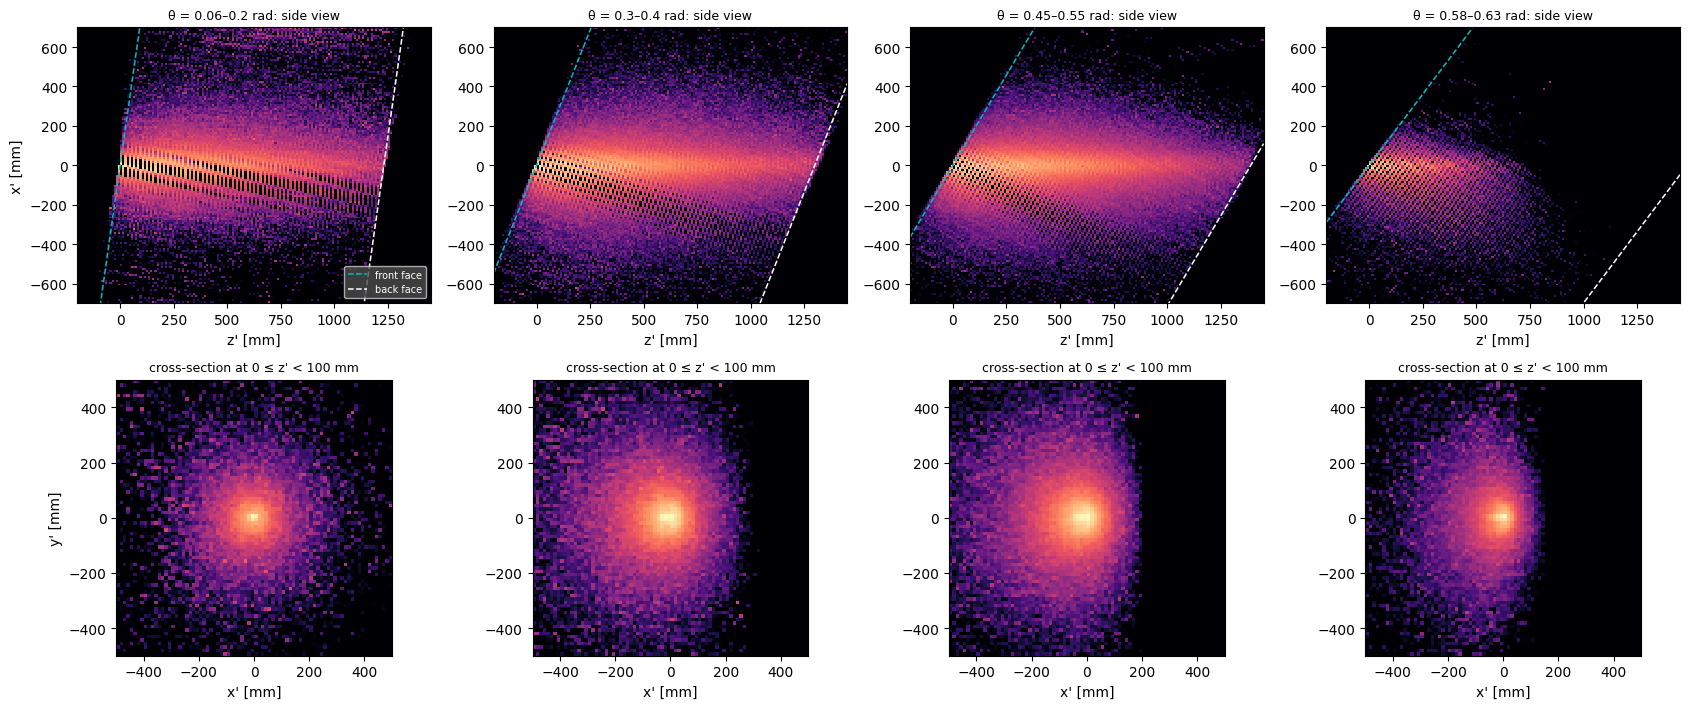

In [5]:
tr = data["train"]
bt = tr.batch(torch.arange(len(tr), device=DEVICE))
th_ev = torch.acos(bt.R[:, 2, 2])
hx, hy, hz, hw = (bt.xyz[:, 0].cpu().numpy(), bt.xyz[:, 1].cpu().numpy(), bt.xyz[:, 2].cpu().numpy(), bt.w.cpu().numpy())
h_th, h_p = th_ev[bt.ev].cpu().numpy(), bt.p[bt.ev].cpu().numpy()
D_ev = (bt.zb * bt.R[:, 2, 2])
fig, axes = plt.subplots(2, 4, figsize=(17, 7.2))
for j, (t0, t1) in enumerate(((0.06, 0.2), (0.3, 0.4), (0.45, 0.55), (0.58, 0.63))):
    m = (h_th >= t0) & (h_th < t1) & (h_p >= 5)
    tm = 0.5 * (t0 + t1)
    mm = m & (np.abs(hy) < 60)
    H, xe, ye = np.histogram2d(hz[mm], hx[mm], bins=[np.linspace(-200, 1450, 166), np.linspace(-700, 700, 141)], weights=hw[mm])
    ax = axes[0, j]
    ax.pcolormesh(xe, ye, H.T + 1e-12, norm=matplotlib.colors.LogNorm(vmin=H.max() * 1e-5, vmax=H.max()), cmap="magma")
    zq = np.linspace(-200, 1450, 50)
    Dm = float(D_ev[(th_ev >= t0) & (th_ev < t1)].median())
    ax.plot(zq, zq / math.tan(tm), "c--", lw=1.1, label="front face"); ax.plot(zq, (zq * math.cos(tm) - Dm) / math.sin(tm), "w--", lw=1.1, label="back face")
    ax.set_ylim(-700, 700); ax.set_title(f"θ = {t0}–{t1} rad: side view", fontsize=9); ax.set_xlabel("z' [mm]")
    mm = m & (hz >= 0) & (hz < 100)
    H, xe, ye = np.histogram2d(hx[mm], hy[mm], bins=[np.linspace(-500, 500, 81), np.linspace(-500, 500, 81)], weights=hw[mm])
    ax = axes[1, j]
    ax.pcolormesh(xe, ye, H.T + 1e-12, norm=matplotlib.colors.LogNorm(vmin=H.max() * 1e-5, vmax=H.max()), cmap="magma")
    ax.set_aspect("equal"); ax.set_title("cross-section at 0 ≤ z' < 100 mm", fontsize=9); ax.set_xlabel("x' [mm]")
axes[0, 0].set_ylabel("x' [mm]"); axes[1, 0].set_ylabel("y' [mm]"); axes[0, 0].legend(fontsize=7, loc="lower right", facecolor="0.3", labelcolor="w")
plt.tight_layout(); plt.show()

### The event-averaged acceptance $\bar A(z', r)$

Averaging $A_\theta$ over the incidence angles of the sample gives a fixed map $\bar A(z', r)$. A body of revolution multiplied by
$\bar A$ is the best *pure* $(z', r \mid p)$ description of what the detector records: this is the cone-shaped front seen in the
network maps of notebooks 05/06. It is computed from the training events only and contains no fitted number.

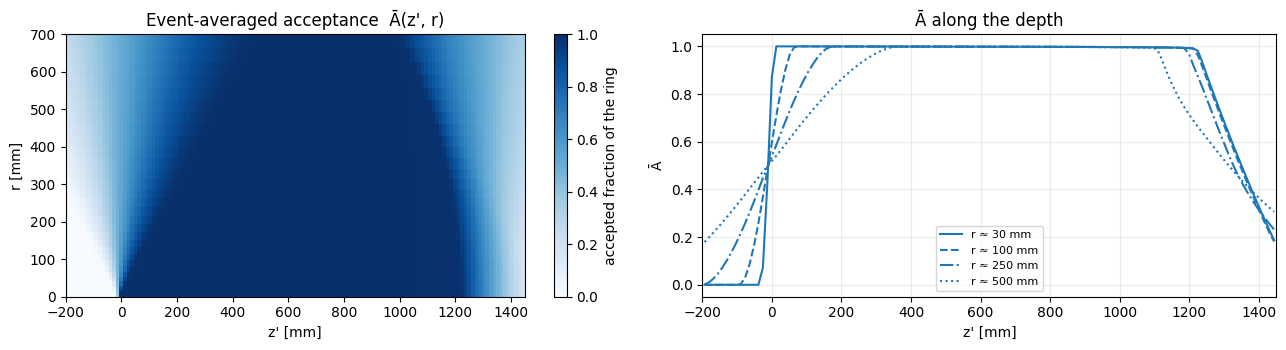

In [6]:
@torch.no_grad()
def mean_acceptance(sh, nsub=4, front=True, back=True):
    tot, n = 0.0, 0
    for bb in sh.batches(256):
        A = event_slab(bb, sh.box, nsub, front, back)
        tot, n = tot + A.sum(0), n + len(A)
    return tot / n


A_BAR = mean_acceptance(data["train"])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
im = ax[0].pcolormesh(Z_EDGES.cpu().numpy(), R_EDGES.cpu().numpy(), A_BAR.T.cpu().numpy(), cmap="Blues", vmin=0, vmax=1)
ax[0].set(title="Event-averaged acceptance  Ā(z', r)", xlabel="z' [mm]", ylabel="r [mm]"); plt.colorbar(im, ax=ax[0], label="accepted fraction of the ring")
zc_np = ZC.cpu().numpy()
for r_sel, ls in ((30, "-"), (100, "--"), (250, "-."), (500, ":")):
    ir = int(torch.argmin((RC - r_sel).abs()))
    ax[1].plot(zc_np, A_BAR[:, ir].cpu().numpy(), ls, color="#1f77b4", label=f"r ≈ {r_sel} mm")
ax[1].set(title="Ā along the depth", xlabel="z' [mm]", ylabel="Ā", xlim=(-200, 1450)); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.25)
plt.tight_layout(); plt.show()

## 4. Two metrics: the report's likelihood and the 3D (slab) likelihood

**The report's metric** (00, `event_nll`): the folded model density at each hit, normalised by the mass of the model in front of
the back face, $M_e = \int_{z' < z_b} \rho$. A body of revolution has mass in front of the tilted front face as well; this mass
is counted in $M_e$ although no hit can ever be recorded there.

**The 3D likelihood:** the same folded density at each hit, but normalised over the region where the event's hits can be,
the slab:

$$\mathrm{NLL}_e = -\sum_i w_i\left[\log g(c_i) - \log M_e^{slab}\right],\qquad
M_e^{slab} = \sum_{(z', r)} P(z', r \mid p)\, A_{\theta_e}(z', r).$$

The two versions differ only in the region over which the model is normalised. Neither is exact: hits can only be recorded in
instrumented cells, and both regions also contain the space outside the calorimeter's transverse outline (outer edge, beam hole)
and the module gaps. An independent check (`review/R1_likelihood`) found that about 0.22–0.24 nat of every model's slab mass, and
≈ 0.27 nat of its mass in the report's normalisation, lies where no hit can be recorded. The part that remains is model-dependent,
so **models are compared only with models trained under the same likelihood**: among slab-trained models the leftover bias of a
paired difference is ≤ 0.001 nat. Re-normalising the report's models over the slab (below) is not an improvement of those models;
it only measures how much mass each of them places in front of the entrance face.

Every number below uses the same split, the same per-event evaluation (`test_nll`: $K = 64$ cell points, fixed seed) and paired
standard errors.

In [7]:
def event_nll_slab(model, b, box, K=N_FOLD, gen=None):
    """Per-event NLL, detector-folded, normalised over the detector slab (tilted front and back faces)."""
    logP = model(b.lnp)
    logrho = logP - LOG_VOL
    pts = fold(b, box, K, gen)
    iz, ir = locate(pts[..., 2], torch.sqrt(pts[..., 0] ** 2 + pts[..., 1] ** 2))
    logg = torch.logsumexp(logrho[b.ev[:, None].expand_as(iz), iz, ir], 1) - math.log(K)
    mass = (logP.exp() * event_slab(b, box)).sum((1, 2))
    ll = logg - torch.log(mass.clamp_min(1e-8))[b.ev]
    return -torch.zeros(len(b.lnp), device=ll.device).index_add_(0, b.ev, b.w * ll), logP


@torch.no_grad()
def test_nll_slab(model, data_, K=N_FOLD_EVAL):
    gen = torch.Generator(device=DEVICE).manual_seed(12345)
    return torch.cat([event_nll_slab(model, b, data_.box, K, gen)[0] for b in data_.batches(128)]).cpu().numpy()


C_STD = globals()                                              # the report's namespace (00_common)
C_SLAB = {**globals(), "event_nll": event_nll_slab, "test_nll": test_nll_slab}


def paired(a, b):
    d = np.asarray(a, np.float64) - np.asarray(b, np.float64)
    return float(d.mean()), float(d.std(ddof=1) / np.sqrt(len(d)))

### The report's saved proton models, evaluated in both metrics (no refit)

The models are loaded from the report's results folder (`/home/user/sofiya/shape-form/results/proton`, read only). The first
column reproduces the report's table exactly.

In [8]:
import sys
sys.path.insert(0, ".")
import shapelab                                                 # helper module of this folder (model loading, fast fit, wrappers)

REPORT = shapelab.baseline_models(C_STD, data)                  # gflash_n1..n6, mlp (L3xH16), cnn, mlp_formula, cnn_formula
NLL = {}                                                        # (model, metric, split) -> per-event NLL
for k in ("gflash_n1", "gflash_n2", "gflash_n6", "mlp_formula", "mlp", "cnn"):
    for metric, fn in (("std", test_nll), ("slab", test_nll_slab)):
        for split in ("val", "test"):
            NLL[(k, metric, split)] = fn(REPORT[k], data[split])
rows = []
for k in ("gflash_n1", "gflash_n2", "gflash_n6", "mlp_formula", "mlp", "cnn"):
    rows.append({"model (report)": k, "params": sum(p.numel() for p in REPORT[k].parameters()),
                 "std: test NLL": NLL[(k, "std", "test")].mean(), "3D: test NLL": NLL[(k, "slab", "test")].mean(),
                 "3D − std": paired(NLL[(k, "slab", "test")], NLL[(k, "std", "test")])[0]})
display(pd.DataFrame(rows).set_index("model (report)").round(4))

,params,std: test NLL,3D: test NLL,3D − std
model (report),,,,
gflash_n1,15,18.287001,18.251801,-0.0352
gflash_n2,21,18.260000,18.227301,-0.0327
gflash_n6,45,18.253599,18.222200,-0.0314
mlp_formula,21,18.267700,18.237499,-0.0302
mlp,881,18.192200,18.172001,-0.0202
cnn,121939,18.190800,18.170700,-0.0202


**What to look for:** the first column is the report's table (GFlash 18.2536, MLP 18.1922, CNN 18.1908). The third column is the
mass each model places in front of the entrance face, where no hit can be recorded: ≈ 0.031 nat for GFlash, ≈ 0.020 for the networks,
which learned the cut as a cone. The product formula $L(z')\,T(r)$ cannot represent the cut; about 18 % of the GFlash–MLP gap of the
report (0.0614 → 0.0502 nat) is this geometric effect.

## 5. The model: shower + primary track + entry spike + end-of-range blob + far halo

With the geometry taken out, the remaining deficit of the GFlash formula is concentrated at low momentum. A proton (mass
$m_p = 0.938$ GeV) differs from a pion here: its kinetic energy $T = \sqrt{p^2 + m_p^2} - m_p$ is small (30 MeV at $p = 0.24$ GeV,
0.43 GeV at 1 GeV, 1.27 GeV at 2 GeV), and below about 1.5 GeV it mostly **stops by ionisation** – a short track ending
at its range – instead of starting a hadronic shower. In addition the origin of the shower frame is the centroid of the first hit
layer, so every event has energy at $(z', r) \approx (0, 0)$: the first layer holds 43 % of the visible energy below 1 GeV and
2.5–5 % above 5 GeV.

The new formula is a sum of physically distinct components, each normalised on the grid, with energy fractions $w_k(p)$:

$$\rho(z', r \mid p) = w_{sh}\, S + w_{tr}\, U + w_{sp}\, D + w_{end}\, E + w_{far}\, H .$$

- **Shower** $S = L(z')\,T(r \mid z')$. Depth: a plateau profile $L \propto \sigma\!\big(\tfrac{z'-z_s}{w_1}\big)\,\sigma\!\big(\tfrac{\ell-z'}{w_2}\big)\,e^{\kappa z'}$
  (fast rise at the shower start $z_s$, exponential fall-off, cut-off at $\ell$; chosen on validation over the GFlash gamma profile
  and over the Bock two-gamma profile of the literature). Cross-section: three terms,
  $$T = f_1\,\frac{e^{-r^2/2\sigma^2}}{2\pi\sigma^2} + f_2\,\frac{1}{\pi}\frac{R^2}{(r^2+R^2)^2} + f_3\,\frac{e^{-r/\lambda}}{2\pi\lambda r},$$
  a narrow electromagnetic core, a Cauchy body and a halo with an **exponential $dE/dr$** (the data are an almost perfect
  exponential in $dE/dr$ between 50 and 350 mm). Widths and fractions vary with depth (linear terms with momentum-dependent slopes,
  plus quadratic terms for the core width and the fractions). The cross-section is normalised on the disc of the grid ($r < 700$ mm)
  at every depth, so that the depth profile is set by $L(z')$ alone: normalised over the infinite plane, a very wide halo whose share
  grows with depth would remove energy from the grid and act as a hidden depth-dependent sink.
- **Primary track** $U$: a tube on the axis that starts behind the first layer, is attenuated as $e^{-z'/\lambda_{att}}$ (the
  primary survives until its first nuclear interaction) and ends at the **range** $R(T) = R_1 T^{k} - R_0$ (a Bragg–Kleeman-type
  range–energy law: low-momentum protons stop), with the Bragg–Kleeman rise of $dE/dx$ towards the end, $(R - z')^{-q}$. Its width
  grows with depth by **multiple scattering** (Highland): $\sigma^2(z') = \sigma_0^2 + \big(c\,(z'/1\,\mathrm{m})^{k_{ms}}/\beta p\big)^2$;
  a small halo $e^{-r/l}/(2\pi l r)$ around it carries the knock-on electrons.
- **Entry spike** $D$: a small Gaussian blob at the origin (the first hit layer), position and widths depending on the momentum. For a
  stopping proton the first layer is part of its track, so the spike fraction is tied to the track length: $f_1 = d_1/(d_1 + L_t)$.
- **End-of-range blob** $E$: a Gaussian at $z' = R(T)$ – the Bragg peak and the products of the stopping particle.
- **Far halo** $H \propto e^{-z'/L_f}\, e^{-r/R_f}/(r + 10\ \mathrm{mm})$ from the entry on: a diffuse deposit far from the axis
  (neutrons and soft photons of the shower).

Every raw parameter is a polynomial in $x = (\ln T - c)/s$ (the kinetic energy instead of $\ln p$; $x \in [-1, 1]$ over the
training range). Parameters that need no energy dependence (depth slopes, track and spike shapes, the range law) are constants.
The only input of the model is $\ln p$.

The variant (gamma or plateau shower, with or without track and attenuation, Bock profile) and the additional terms (spike shape,
end blob, far halo; multiple scattering, knock-on halo, Bragg rise, depth curvature) were chosen on the validation set at degree 2
(`scripts/particle_pipeline.py`, `scripts/variants_v2.py`, `scripts/variants_v3.py`; the same protocol for all four particles, see
`README.md`); the checkpoints below come from that run (`results/particles/proton/`).

Fitting: the same likelihood (3D or the report's), Adam with a cosine-decaying learning rate (`shapelab.fit_fast`, batch 256,
4000 steps, best validation state kept). The degree $n$ is chosen as in notebook 01: train $n = 1, \dots, 6$ (each started from
the previous solution), $n \le 6$ as for GFlash in 01, take the lowest validation NLL, and choose the smallest $n$ within one paired
standard error of it. As for GFlash in 01, the rule picks the top rung: the paired SE between nested, warm-started rungs is tiny,
while the gains beyond $n = 2$ are small. The degree-2 rung is therefore reported alongside.

In [9]:
from particle_shape import ParticleShape, MASS
from proton_shape import ProtonShape
import inspect
print(inspect.getsource(ParticleShape.log_shower))
print(inspect.getsource(ProtonShape.log_track))
print(inspect.getsource(ParticleShape.log_track))
print(inspect.getsource(ProtonShape.range_mm))
print(inspect.getsource(ParticleShape.components))

    def log_shower(self, th, Z, R):
        if self.long == "gamma":
            return super().log_shower(th, Z, R)
        if self.long == "bock":
            th2 = dict(th, z0=torch.zeros_like(th["z_st"]), log_tmax=torch.zeros_like(th["z_st"]), log_am1=torch.zeros_like(th["z_st"]))
            lat = super().log_shower(th2, Z, R) - families.long_gamma(Z, th2["z0"], torch.exp(th2["log_tmax"]), torch.exp(th2["log_am1"]))
            return torch.log(self.bock_face(th) + 1e-30)[:, :, None] + lat
        # plateau depth profile (the report's cylinder, 04): fast rise at zs, slow change, cut-off at ell
        L = (F.logsigmoid((Z - th["zs"]) / torch.exp(th["log_w1"])) + F.logsigmoid((torch.exp(th["log_ell"]) - Z) / torch.exp(th["log_w2"]))
             + th["kappa"] * Z / 1000)
        th2 = dict(th, z0=torch.zeros_like(th["zs"]), log_tmax=torch.zeros_like(th["zs"]), log_am1=torch.zeros_like(th["zs"]))
        lat = super().log_shower(th2, Z, R) - families.long_gamma(Z, th2["z0"], torch.e

In [10]:
LNP0, LNP_S = shapelab.lnp_center_scale(data)
A_BAR_DEV = A_BAR.to(DEVICE)
FINAL = "results/particles/proton"                              # written by scripts/particle_pipeline.py proton
KW, _, _, TAG, PIPE_TEST, ROUND = shapelab.final_kwargs(FINAL)   # the variant chosen on validation (final round)
print("final formula:", PIPE_TEST["variant"], KW)


def make(n, metric):
    kw, degrees, *_ = shapelab.final_kwargs(FINAL, n=n, metric=metric)
    core = ParticleShape(C_STD, MASS["proton"], lnp0=LNP0, lnp_s=LNP_S, degree=n, degrees=degrees or None, **kw).to(DEVICE)
    return shapelab.WithAcceptance(core, A_BAR_DEV).to(DEVICE) if metric == "std" else core


def load_or_fit(n, metric, prev=None):
    """Load the trained rung (written by scripts/particle_pipeline.py); otherwise train it here."""
    path = f"{FINAL}/{TAG}_{'std' if metric == 'std' else 'slab'}_n{n}.pt"
    m = make(n, metric)
    if os.path.exists(path):
        m.load_state_dict(torch.load(path, map_location=DEVICE, weights_only=False)["state"])
        return m.eval()
    core = m.base if metric == "std" else m
    core.init_from_data(C_STD, data)
    if prev is not None:
        core.warm_start(prev.base if metric == "std" else prev)
    shapelab.fit_fast(C_SLAB if metric == "slab" else C_STD, data, m, steps=4000, log=None)
    os.makedirs(FINAL, exist_ok=True)
    torch.save({"state": m.state_dict()}, path)
    return m.eval()


LADDER, CHOSEN = {}, {}
for metric, tnll in (("slab", test_nll_slab), ("std", test_nll)):
    prev, val = None, {}
    for n in range(1, 7):
        prev = LADDER[(metric, n)] = load_or_fit(n, metric, prev)
        val[n] = tnll(prev, data["val"])
    n_star = min(val, key=lambda k: val[k].mean())
    d = {n: paired(val[n], val[n_star]) for n in val}
    CHOSEN[metric] = min(n for n in val if n == n_star or d[n][0] < d[n][1])
    print(f"{metric:4s} metric:", " | ".join(f"n={n}: {LADDER[(metric, n)].n_params()} params, val {val[n].mean():.4f} (Δ vs n* {d[n][0]:+.4f} ± {d[n][1]:.4f})" for n in val),
          f"→ chosen n = {CHOSEN[metric]}")

final formula: plateau_track+all+all4 {'long': 'plateau', 'track': True, 'spike': True, 'att': True, 'far': True, 'endblob': True, 'ms': True, 'curv': True, 'track_halo': True, 'bragg': True}


slab metric: n=1: 66 params, val 18.1810 (Δ vs n* +0.0104 ± 0.0009) | n=2: 87 params, val 18.1724 (Δ vs n* +0.0017 ± 0.0002) | n=3: 101 params, val 18.1718 (Δ vs n* +0.0011 ± 0.0002) | n=4: 115 params, val 18.1714 (Δ vs n* +0.0008 ± 0.0002) | n=5: 129 params, val 18.1708 (Δ vs n* +0.0002 ± 0.0000) | n=6: 143 params, val 18.1706 (Δ vs n* +0.0000 ± 0.0000) → chosen n = 6


std  metric: n=1: 66 params, val 18.2006 (Δ vs n* +0.0028 ± 0.0003) | n=2: 87 params, val 18.1990 (Δ vs n* +0.0012 ± 0.0002) | n=3: 101 params, val 18.1984 (Δ vs n* +0.0006 ± 0.0001) | n=4: 115 params, val 18.1983 (Δ vs n* +0.0005 ± 0.0001) | n=5: 129 params, val 18.1981 (Δ vs n* +0.0002 ± 0.0000) | n=6: 143 params, val 18.1978 (Δ vs n* +0.0000 ± 0.0000) → chosen n = 6


**The observable region.** The 3D likelihood is blind to model mass in cells that no event's slab ever covers (the small-$r$
region in front of the entrance face, $z' \lesssim -r\tan\theta_{max}$): such mass changes no event's normalisation, so the fit is
free to put mass there (here 5–9 % of the map). Physically that region is outside the calorimeter. For every figure and body below the
3D-trained model is therefore restricted to the cells covered by at least one training slab ($\bar A > 0$) and renormalised; the 3D
NLL is unchanged by this (verified below).

In [11]:
class Observable(nn.Module):
    """The model restricted to the cells that at least one training slab covers (A_bar > 0), renormalised."""

    def __init__(self, base, mask):
        super().__init__()
        self.base = base
        self.register_buffer("logm", torch.log(mask.float().clamp_min(1e-30)))

    def forward(self, lnp):
        lp = self.base(lnp) + self.logm
        return F.log_softmax(lp.reshape(len(lnp), -1), 1).reshape(lp.shape)

    def n_params(self):
        return self.base.n_params()


OBS_MASK = (A_BAR_DEV > 0)
SHAPE = Observable(LADDER[("slab", CHOSEN["slab"])], OBS_MASK).eval()
with torch.no_grad():
    lost = (LADDER[("slab", CHOSEN["slab"])](torch.log(torch.tensor([0.5, 2.0, 15.0], device=DEVICE))).exp() * (~OBS_MASK)).sum((1, 2))
t_full, t_obs = test_nll_slab(LADDER[("slab", CHOSEN["slab"])], data["test"]), test_nll_slab(SHAPE, data["test"])
print(f"never-observable cells: {int((~OBS_MASK).sum())} of {OBS_MASK.numel()}; mass there at p = 0.5 / 2 / 15 GeV: "
      + " / ".join(f"{float(x):.3f}" for x in lost)
      + f" | 3D test NLL {t_full.mean():.6f} -> {t_obs.mean():.6f} after restriction (max per-event change {np.abs(t_obs - t_full).max():.1e})")

never-observable cells: 152 of 4096; mass there at p = 0.5 / 2 / 15 GeV: 0.070 / 0.086 / 0.054 | 3D test NLL 18.166021 -> 18.166021 after restriction (max per-event change 2.8e-04)


## 6. Results

### 6.1 Accuracy, like with like

Every model is compared with models **trained under the same likelihood**. In the report's metric a pure $(z', r \mid p)$ model may
contain the fixed geometric template $\bar A$ ("× Ā", 4096 numbers computed from the training events' angles and depths, not fitted).
Reference refits use exactly the same optimiser and protocol as the new formula (`fit_fast`, 4000 steps per rung, degree ladder
1–6, warm start, 1-SE rule; `scripts/particle_pipeline.py`); the network reference is the report's MLP fine-tuned with the same
optimiser. The report's own models appear only in the report's metric. "NEW, compact" is the degree-2 rung.

In [12]:
def strip(sd, prefix):
    return {k[len(prefix):]: v for k, v in sd.items() if k.startswith(prefix)}


NB = PIPE_TEST["degrees"]                                        # chosen degrees of the reference ladders (1-SE on validation)
ck = torch.load(f"{FINAL}/base_std_n{NB['base_std']}.pt", map_location=DEVICE, weights_only=False)["state"]
gacc = shapelab.WithAcceptance(Formula("gamma", "core_tail", degree=NB["base_std"], lnp0=LNP0, lnp_s=LNP_S), A_BAR_DEV).to(DEVICE)
gacc.load_state_dict({**{"base." + k: v for k, v in strip(ck, "base.f.").items()}, "logA": ck["logA"]})
g6 = Formula("gamma", "core_tail", degree=NB["base_slab"], lnp0=LNP0, lnp_s=LNP_S).to(DEVICE)
g6.load_state_dict(strip(torch.load(f"{FINAL}/base_slab_n{NB['base_slab']}.pt", map_location=DEVICE, weights_only=False)["state"], "f."))
REF = {"GFlash × Ā (refit)": gacc.eval(), "GFlash (3D refit)": g6.eval()}
for tag, key in (("mlp_std", "MLP fine-tuned (report metric)"), ("mlp_slab", "MLP fine-tuned (3D)")):
    m_ = FieldModel(16, 3).to(DEVICE)
    m_.load_state_dict(torch.load(f"{FINAL}/{tag}.pt", map_location=DEVICE, weights_only=False)["state"])
    REF[key] = m_.eval()
NEW = {"std": LADDER[("std", CHOSEN["std"])], "slab": LADDER[("slab", CHOSEN["slab"])]}

TABLE = [  # (name, params, model trained in the report's metric, model trained in the 3D metric)
    ("GFlash n=6 (report)", 45, REPORT["gflash_n6"], None),
    (f"GFlash (× Ā / 3D refit, n = {NB['base_std']} / {NB['base_slab']})", REF["GFlash × Ā (refit)"].n_params(), REF["GFlash × Ā (refit)"], REF["GFlash (3D refit)"]),
    ("NEW, compact (n = 2)", LADDER[("std", 2)].n_params(), LADDER[("std", 2)], LADDER[("slab", 2)]),
    ("NEW (1-SE)", NEW["std"].n_params(), NEW["std"], NEW["slab"]),
    ("MLP L3xH16 (report)", 881, REPORT["mlp"], None),
    ("MLP L3xH16 (fine-tuned)", 881, REF["MLP fine-tuned (report metric)"], REF["MLP fine-tuned (3D)"]),
    ("CNN (report)", 121939, REPORT["cnn"], None),
]
BASE = {"std": TABLE[1][0], "3D": TABLE[1][0]}
rows, PER = [], {}
for name, npar, ms, m3d in TABLE:
    for metric, m, fn in (("std", ms, test_nll), ("3D", m3d, test_nll_slab)):
        if m is not None:
            for split in ("val", "test"):
                PER[(name, metric, split)] = fn(m, data[split])
for name, npar, ms, m3d in TABLE:
    r = {"model": name, "params": npar}
    for metric in ("std", "3D"):
        if (name, metric, "test") not in PER:
            r.update({f"{metric}: val": np.nan, f"{metric}: test": np.nan, f"{metric}: Δtest vs GFlash refit": ""})
            continue
        r[f"{metric}: val"] = PER[(name, metric, "val")].mean()
        r[f"{metric}: test"] = PER[(name, metric, "test")].mean()
        d, se = paired(PER[(name, metric, "test")], PER[(BASE[metric], metric, "test")])
        r[f"{metric}: Δtest vs GFlash refit"] = f"{d:+.4f} ± {se:.4f}"
    rows.append(r)
ACC = pd.DataFrame(rows).set_index("model")
display(ACC.style.format({c: "{:.4f}" for c in ACC.columns if c.endswith("val") or c.endswith("test")}, na_rep="–"))
ACC.to_csv(f"{FINAL}/notebook_accuracy_table.csv")

T = lambda name, metric: PER[(name, metric, "test")].mean()
MLPN = "MLP L3xH16 (fine-tuned)"
for metric, label in (("std", "report metric"), ("3D", "3D metric")):
    g, n2, n6, mlp = T(BASE[metric], metric), T("NEW, compact (n = 2)", metric), T("NEW (1-SE)", metric), T(MLPN, metric)
    print(f"{label}: share of the (GFlash refit → fine-tuned MLP) gap closed by the new formula: 1-SE {(g - n6) / (g - mlp):.0%}, n = 2 {(g - n2) / (g - mlp):.0%}"
          f"  | remaining gap to the MLP: {paired(PER[('NEW (1-SE)', metric, 'test')], PER[(MLPN, metric, 'test')])[0]:+.4f}")
r0 = T("GFlash n=6 (report)", "std")
print(f"report metric, decomposition of the report's GFlash → report MLP gap ({r0 - T('MLP L3xH16 (report)', 'std'):.4f} nat): geometric template Ā "
      f"{r0 - T(BASE['std'], 'std'):.4f}, new formula {T(BASE['std'], 'std') - T('NEW (1-SE)', 'std'):.4f}, left {T('NEW (1-SE)', 'std') - T('MLP L3xH16 (report)', 'std'):.4f}")

,params,std: val,std: test,std: Δtest vs GFlash refit,3D: val,3D: test,3D: Δtest vs GFlash refit
model,,,,,,,
GFlash n=6 (report),45,18.2587,18.2536,+0.0205 ± 0.0009,–,–,
"GFlash (× Ā / 3D refit, n = 6 / 6)",45,18.2392,18.2331,+0.0000 ± 0.0000,18.2075,18.2003,+0.0000 ± 0.0000
"NEW, compact (n = 2)",87,18.1990,18.1952,-0.0379 ± 0.0016,18.1724,18.1676,-0.0327 ± 0.0015
NEW (1-SE),143,18.1978,18.1940,-0.0391 ± 0.0016,18.1706,18.1660,-0.0343 ± 0.0015
MLP L3xH16 (report),881,18.1958,18.1922,-0.0408 ± 0.0017,–,–,
MLP L3xH16 (fine-tuned),881,18.1934,18.1898,-0.0432 ± 0.0017,18.1659,18.1614,-0.0390 ± 0.0016
CNN (report),121939,18.1950,18.1908,-0.0422 ± 0.0016,–,–,


report metric: share of the (GFlash refit → fine-tuned MLP) gap closed by the new formula: 1-SE 90%, n = 2 88%  | remaining gap to the MLP: +0.0042
3D metric: share of the (GFlash refit → fine-tuned MLP) gap closed by the new formula: 1-SE 88%, n = 2 84%  | remaining gap to the MLP: +0.0047
report metric, decomposition of the report's GFlash → report MLP gap (0.0614 nat): geometric template Ā 0.0205, new formula 0.0391, left 0.0018


### 6.2 Where the gain comes from: per momentum bin (3D metric, test set)

Paired difference to the GFlash formula refitted with the same 3D likelihood, in every 1 GeV bin. Negative = better.

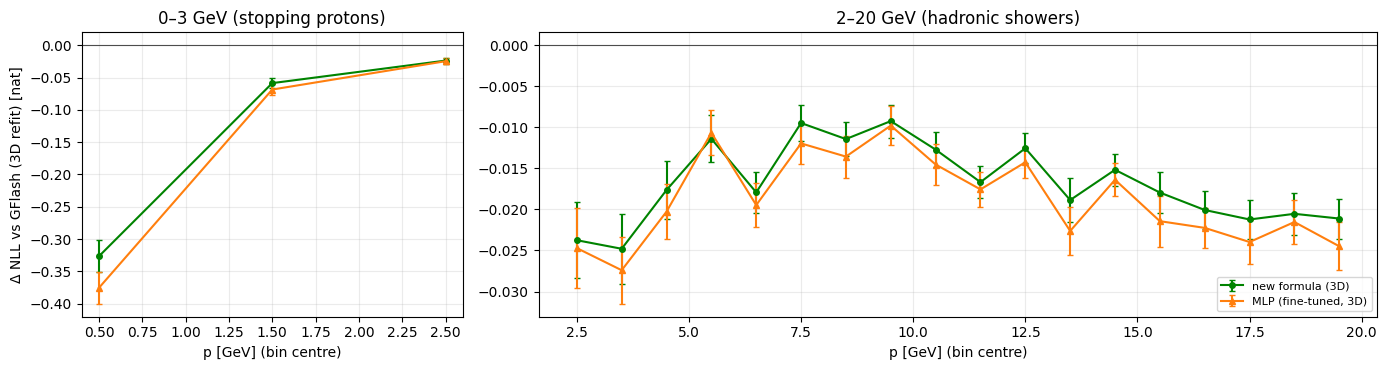

new formula − fine-tuned MLP (3D): bins 2–19 +0.0019 ± 0.0003 per event (positive in 17 of 18 bins); bins 0–1 hold 63% of the remaining gap


In [13]:
bins_te = data["test"].ev["bin"].cpu().numpy()
SER = {"new formula (3D)": ("NEW (1-SE)", "#008300", "o"), "MLP (fine-tuned, 3D)": (MLPN, "#ff7f0e", "^")}
base = PER[(BASE["3D"], "3D", "test")]
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1, 2.2]})
for lab, (key, col, mk) in SER.items():
    d = PER[(key, "3D", "test")] - base
    mean = np.array([d[bins_te == b].mean() for b in range(20)])
    se = np.array([d[bins_te == b].std(ddof=1) / np.sqrt((bins_te == b).sum()) for b in range(20)])
    for a_, sl in ((ax[0], slice(0, 3)), (ax[1], slice(2, 20))):
        a_.errorbar(np.arange(20)[sl] + 0.5, mean[sl], se[sl], fmt=mk + "-", color=col, ms=4, lw=1.5, capsize=2, label=lab)
for a_ in ax:
    a_.axhline(0, color="0.3", lw=0.8); a_.grid(alpha=0.25); a_.set_xlabel("p [GeV] (bin centre)")
ax[0].set(title="0–3 GeV (stopping protons)", ylabel="Δ NLL vs GFlash (3D refit) [nat]")
ax[1].set(title="2–20 GeV (hadronic showers)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
dn = PER[("NEW (1-SE)", "3D", "test")] - PER[(MLPN, "3D", "test")]
hi = bins_te >= 2
print(f"new formula − fine-tuned MLP (3D): bins 2–19 {dn[hi].mean():+.4f} ± {dn[hi].std(ddof=1) / np.sqrt(hi.sum()):.4f} per event "
      f"(positive in {sum(dn[bins_te == b].mean() > 0 for b in range(2, 20))} of 18 bins); "
      f"bins 0–1 hold {dn[~hi].sum() / dn.sum():.0%} of the remaining gap")

**What to look for:** the new formula is better than the refitted GFlash in every bin: by ≈ 0.3 nat below 1 GeV, 0.06 nat at
1–2 GeV and 0.01–0.025 nat above 2 GeV. The network trained with the same likelihood is still better: by a small but systematic
amount in almost every bin above 2 GeV (printed above), and more below 2 GeV, where about 60 % of the remaining gap sits.

### 6.3 The fitted formula

Energy fractions of the components and the fitted range of the stopping track as functions of the momentum, and the
shower's cross-section parameters at two depths. All curves come from the chosen 3D model; the parameter table follows.

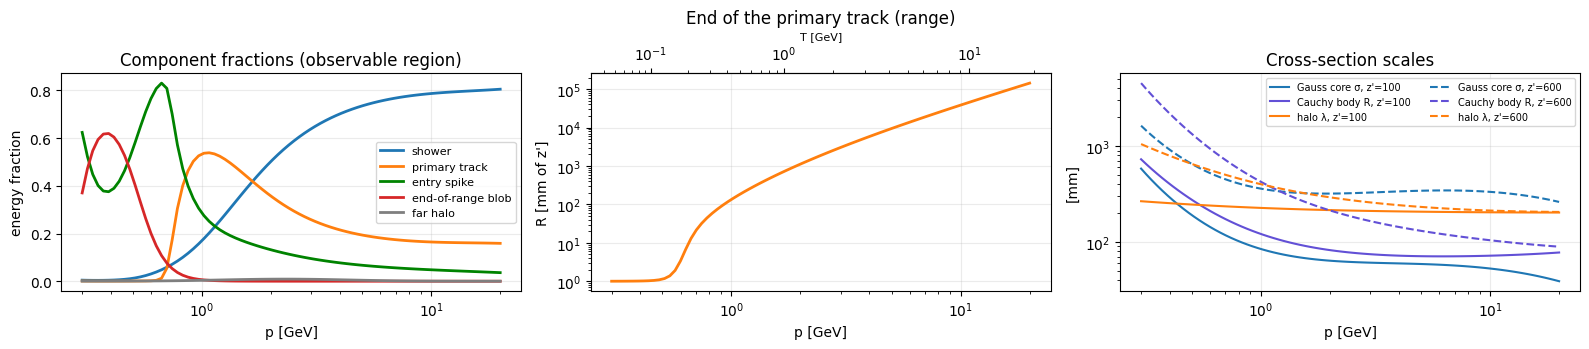

### New proton formula (3D likelihood, degree 6)

| parameter | value, $x=(\ln(T/\mathrm{GeV}) +0.1055)/3.054$ |
|---|---|
| `zs` | $-1.494 +29.37\,x +27.32\,x^2 +13.24\,x^3 +6.831\,x^4 +4.058\,x^5 +1.351\,x^6$ |
| `log_w1` | $+4.594 -0.7044\,x +0.9203\,x^2 +0.08295\,x^3 -0.3094\,x^4 -0.1341\,x^5 -0.06513\,x^6$ |
| `log_ell` | $+5.5 +2.662\,x +0.1739\,x^2 -0.6159\,x^3 -0.6127\,x^4 -0.0779\,x^5 +0.1632\,x^6$ |
| `log_w2` | $+5.557 +1.261\,x +0.09128\,x^2 -1.903\,x^3 -0.379\,x^4 -0.6147\,x^5 +0.321\,x^6$ |
| `kappa` | $-2.914 +0.4563\,x +0.007618\,x^2 -0.2396\,x^3 -0.1021\,x^4 +0.05784\,x^5 +0.0839\,x^6$ |
| `log_sig` | $+3.75 -0.7117\,x +1.178\,x^2 -0.7385\,x^3 -0.3328\,x^4 -0.06241\,x^5 +0.04924\,x^6$ |
| `log_R` | $+4.292 -0.7822\,x +1.103\,x^2 -0.2295\,x^3 -0.1533\,x^4 +0.004105\,x^5 +0.08862\,x^6$ |
| `log_lam` | $+5.309$ |
| `logit_1` | $-2.494 +0.01576\,x -0.07825\,x^2 +0.4226\,x^3 +0.3173\,x^4 +0.1813\,x^5 -0.00696\,x^6$ |
| `logit_2` | $+2.208 -1.273\,x -0.1483\,x^2 +0.6427\,x^3 +0.3686\,x^4 +0.121\,x^5 +0.006347\,x^6$ |
| `s_sig` | $+4.855 +0.8958\,x -0.2121\,x^2$ |
| `s_R` | $+2.103 -1.714\,x -0.1085\,x^2$ |
| `s_lam` | $+0.7645 -1.403\,x +0.6665\,x^2$ |
| `s_1` | $+0.1828 -1.772\,x -1.054\,x^2$ |
| `s_2` | $+2.886 -0.7205\,x -1.256\,x^2$ |
| `logit_sp` | $-1.171 -2.938\,x +0.7109\,x^2 +1.302\,x^3 -0.4324\,x^4 -0.07137\,x^5 -0.1893\,x^6$ |
| `sp_z` | $-3.173 -2.96\,x -12.38\,x^2$ |
| `log_sp_sz` | $+2.821 +0.7436\,x -0.3943\,x^2$ |
| `log_sp_sr` | $+2.37 +0.2015\,x -0.1202\,x^2$ |
| `logit_tr` | $-0.2999 -3.507\,x +1.862\,x^2 +0.7995\,x^3 -0.332\,x^4 -0.06903\,x^5 -0.1765\,x^6$ |
| `log_R1` | $+6.63$ |
| `k_R` | $+1.779$ |
| `R0` | $+36.53$ |
| `log_wR` | $-2.85$ |
| `kap` | $+2.461$ |
| `zt0` | $+24.08$ |
| `log_st` | $+2.919$ |
| `log_d1` | $+3.458$ |
| `log_latt` | $+5.583$ |
| `logit_far` | $-4.982 +1.811\,x -4.361\,x^2 -2.283\,x^3 -0.9807\,x^4 -1.484\,x^5 +0.02221\,x^6$ |
| `log_Lf` | $+6.87$ |
| `log_Rf` | $+17.83$ |
| `logit_end` | $-8.172 -11.76\,x +4.554\,x^2 +1.887\,x^3 -3.455\,x^4 +2.678\,x^5 -1.045\,x^6$ |
| `log_sez` | $+4.334$ |
| `log_ser` | $+4.395$ |
| `logit_th` | $-1.715 +4.92\,x -5.477\,x^2 -0.9355\,x^3 +0.2077\,x^4 +0.8714\,x^5 +0.7656\,x^6$ |
| `log_lh` | $+4.401$ |
| `q_bk` | $+0.8039$ |
| `q_sig` | $-2.468$ |
| `q_1` | $+1.759$ |
| `q_2` | $-2.633$ |
| `log_cms` | $+5.653$ |
| `ms_pow` | $+2.374$ |

Number of parameters: **143**

In [14]:
M = NEW["slab"]
with torch.no_grad():
    pg = torch.logspace(math.log10(0.3), math.log10(20), 80, device=DEVICE)
    lw, comp, th = M.components(torch.log(pg))
    obs = OBS_MASK.float()                                         # energy fractions inside the observable region
    wv = [x.exp().flatten() * (c_.exp() * obs).sum((1, 2)) if x is not None else None for x, c_ in zip(lw, comp)]
    tot = sum(v for v in wv if v is not None)
    w = [(v / tot).cpu().numpy() if v is not None else None for v in wv]
    Rr = M.range_mm(th).flatten().cpu().numpy()
    T = (pg ** 2 / (torch.sqrt(pg ** 2 + 0.938272 ** 2) + 0.938272)).cpu().numpy()
pgn = pg.cpu().numpy()
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
COMP_NAMES = ["shower", "primary track", "entry spike"] + (["end-of-range blob"] if M.endblob else []) + (["far halo"] if M.far else [])
COMP_COLS = ["#1f77b4", "#ff7f0e", "#008300", "#d62728", "#7f7f7f"]
for lab, ww, col in zip(COMP_NAMES, w, COMP_COLS):
    if ww is not None:
        ax[0].plot(pgn, ww, color=col, lw=2, label=lab)
ax[0].set(xscale="log", xlabel="p [GeV]", ylabel="energy fraction", title="Component fractions (observable region)"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.25)
ax[1].plot(pgn, Rr, color="#ff7f0e", lw=2, label="fitted track end R(T)")
ax[1].set(xscale="log", yscale="log", xlabel="p [GeV]", ylabel="R [mm of z']", title="End of the primary track (range)"); ax[1].grid(alpha=0.25)
ax1b = ax[1].secondary_xaxis("top", functions=(lambda p: np.sqrt(np.clip(p, 1e-6, None) ** 2 + 0.938272 ** 2) - 0.938272,
                                               lambda t: np.sqrt(np.clip((np.clip(t, 1e-6, None) + 0.938272) ** 2 - 0.938272 ** 2, 1e-12, None))))
ax1b.set_xlabel("T [GeV]", fontsize=8)
zsel = [100.0, 600.0]
for k, zz_ in enumerate(zsel):
    zk = zz_ / 1000
    q = lambda k_: th[k_] * zk * zk if k_ in th else 0.0
    sig = torch.exp(th["log_sig"] + th["s_sig"] * zk + q("q_sig")).flatten().cpu().numpy()
    Rm = torch.exp(th["log_R"] + th["s_R"] * zk).flatten().cpu().numpy()
    lam = torch.exp(th["log_lam"] + th["s_lam"] * zk).flatten().cpu().numpy()
    ls = "-" if k == 0 else "--"
    ax[2].plot(pgn, sig, ls, color="#1f77b4", label=f"Gauss core σ, z'={zz_:.0f}")
    ax[2].plot(pgn, Rm, ls, color="#6250d6", label=f"Cauchy body R, z'={zz_:.0f}")
    ax[2].plot(pgn, lam, ls, color="#ff7f0e", label=f"halo λ, z'={zz_:.0f}")
ax[2].set(xscale="log", yscale="log", xlabel="p [GeV]", ylabel="[mm]", title="Cross-section scales"); ax[2].legend(fontsize=7, ncol=2); ax[2].grid(alpha=0.25)
plt.tight_layout(); plt.show()
display(Markdown(M.describe(f"New proton formula (3D likelihood, degree {CHOSEN['slab']})")))

**Reading the curves.** Below 1 GeV most of the energy is in the entry spike, the track and the end-of-range blob (a stopping
proton); the shower takes over between 1 and 3 GeV and carries ≈ 80 % at high momentum. The track keeps 16–20 % above 5 GeV: the
primary proton before its first nuclear interaction (fitted attenuation length ≈ 270 mm) together with the narrow core of the shower,
which its small halo takes over – above 2 GeV this split is effective. The track end grows with the kinetic energy as a power law,
$R \propto T^{k}$ with $k \approx 1.8$, the Bragg–Kleeman exponent of the proton range (1.77); as an effective length of the mean energy
profile it is shorter than the CSDA range of a free proton. Below ≈ 0.6 GeV the split is effective as well: the proton stops in the
first layers, and the spike and the end blob describe a short, wide deposit. The far halo stays below 1 %. In the shower's
cross-section the Gaussian term widens strongly with depth (≈ 50 mm at $z' = 100$ mm, ≈ 300 mm at 600 mm), the Cauchy body has
R ≈ 70–80 mm at 100 mm and the halo λ ≈ 200–260 mm.

### 6.4 Data vs model: profiles (3D metric)

Deposits sampled from each model inside the event's slab and folded with its cell (the 3D analogue of `sample_folded` of 00),
compared with the test hits in five momentum bins.

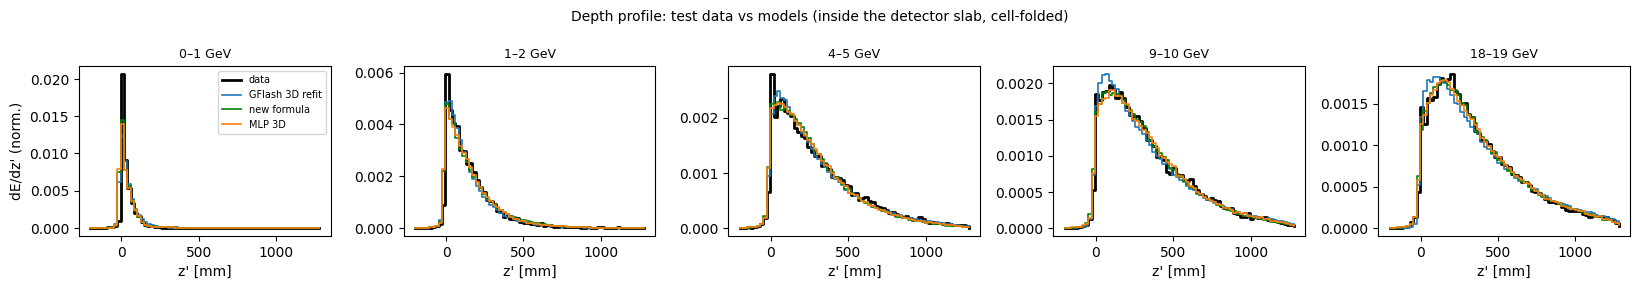

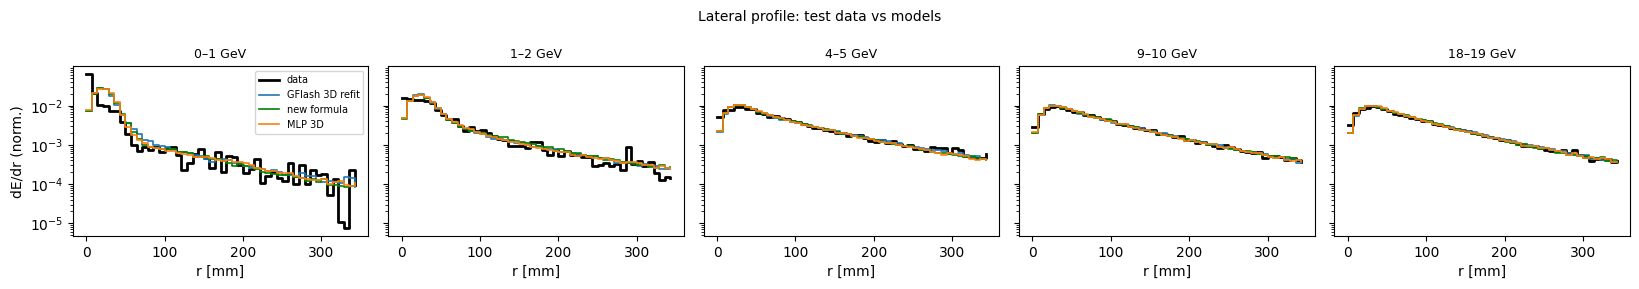

In [15]:
@torch.no_grad()
def sample_folded_slab(model, data_, M_=200, seed=7):
    """Deposits drawn from the model's body of revolution, kept only inside the event's slab (rejection), folded with the cell."""
    gen = torch.Generator(device=DEVICE).manual_seed(seed)
    out = []
    for b in data_.batches(128):
        n = len(b.lnp)
        cell = torch.multinomial(model(b.lnp).exp().reshape(n, -1), M_, True, generator=gen)
        iz, ir = cell // N_R, cell % N_R
        u = torch.rand(n, M_, 3, device=DEVICE, generator=gen)
        z = Z_EDGES[iz] + u[..., 0] * DZ
        r = torch.sqrt(R_EDGES[ir] ** 2 + u[..., 1] * (R_EDGES[ir + 1] ** 2 - R_EDGES[ir] ** 2))
        pts = torch.stack([r * torch.cos(6.2832 * u[..., 2]), r * torch.sin(6.2832 * u[..., 2]), z], -1)
        ct = b.R[:, 2, 2][:, None]
        zt = pts[..., 2] * ct - pts[..., 0] * torch.sqrt(1 - ct ** 2)
        keep = (zt >= -float(data_.box[2]) / 2) & (zt <= b.zb[:, None] * ct)
        box = (torch.rand(n, M_, 3, device=DEVICE, generator=gen) - 0.5) * data_.box
        pts = pts + torch.einsum("bij,bmj->bmi", b.R, box)
        w_ev = (1.0 / keep.sum(1).clamp_min(1)).float()[:, None].expand(-1, M_)
        out.append(pd.DataFrame({"z": pts[..., 2][keep].cpu().numpy(), "r": torch.sqrt(pts[..., 0] ** 2 + pts[..., 1] ** 2)[keep].cpu().numpy(),
                                 "p": b.p[:, None].expand(-1, M_)[keep].cpu().numpy(), "w": w_ev[keep].cpu().numpy()}))
    return pd.concat(out, ignore_index=True)


COLORS.update({"GFlash 3D refit": "#1f77b4", "new formula": "#008300", "MLP 3D": "#ff7f0e"})
hits_te = data["test"].hits()
SAMP = {"GFlash 3D refit": sample_folded_slab(REF["GFlash (3D refit)"], data["test"]),
        "new formula": sample_folded_slab(NEW["slab"], data["test"]),
        "MLP 3D": sample_folded_slab(REF["MLP fine-tuned (3D)"], data["test"])}
SHOW_BINS = (0, 1, 4, 9, 18)
profile_plot(hits_te, SAMP, "z", "Depth profile: test data vs models (inside the detector slab, cell-folded)")
profile_plot(hits_te, SAMP, "r", "Lateral profile: test data vs models")

### 6.5 The 3D shape

**Top:** the true (de-convolved) density of the new formula as a body of revolution, $\log_{10}\rho$ in $(z', \pm r)$ (as
`shape_map` in 01–06), restricted to the observable region (grey: cells that no event's slab covers). **Middle:** the same body cut
by the detector planes for a typical incidence angle ($\theta = 0.45$ rad), side view $(z', x')$ through the axis: this is the 3D
shape the detector records. **Bottom:** the components at 1 GeV.

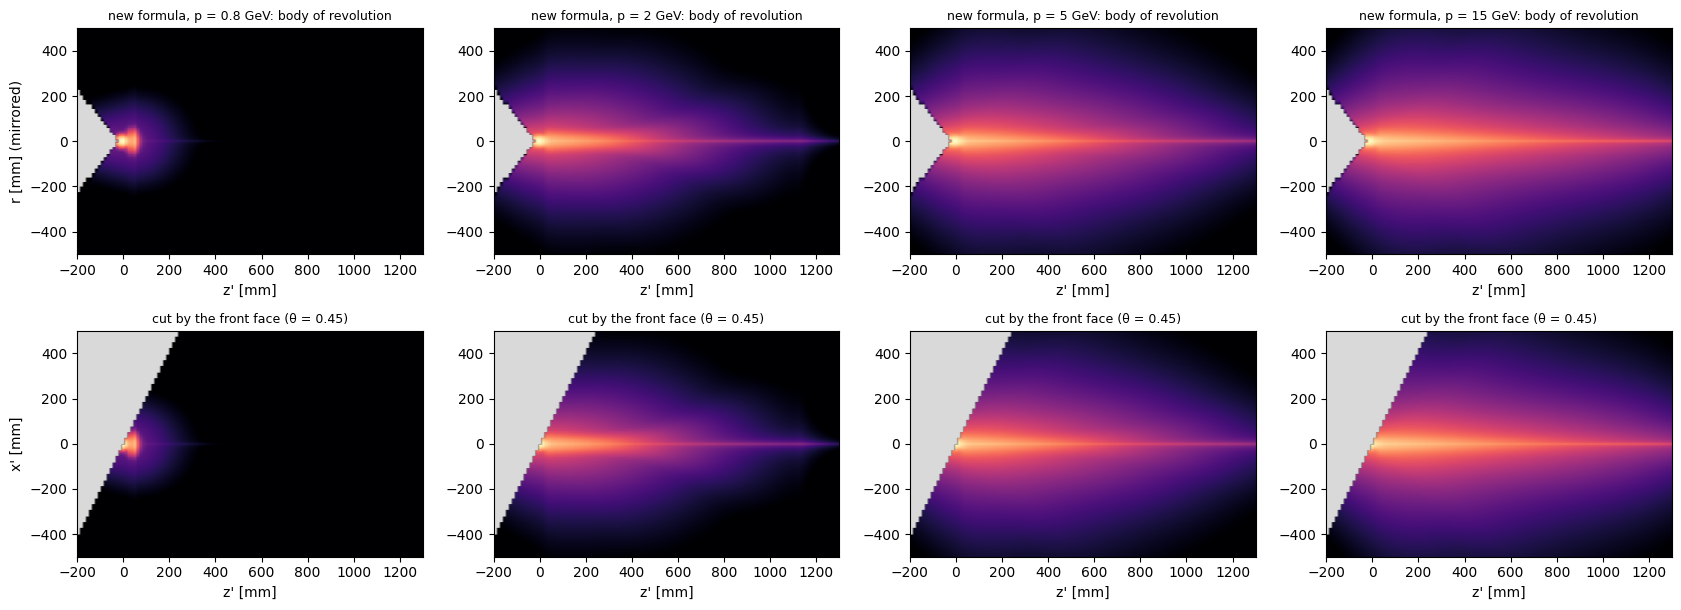

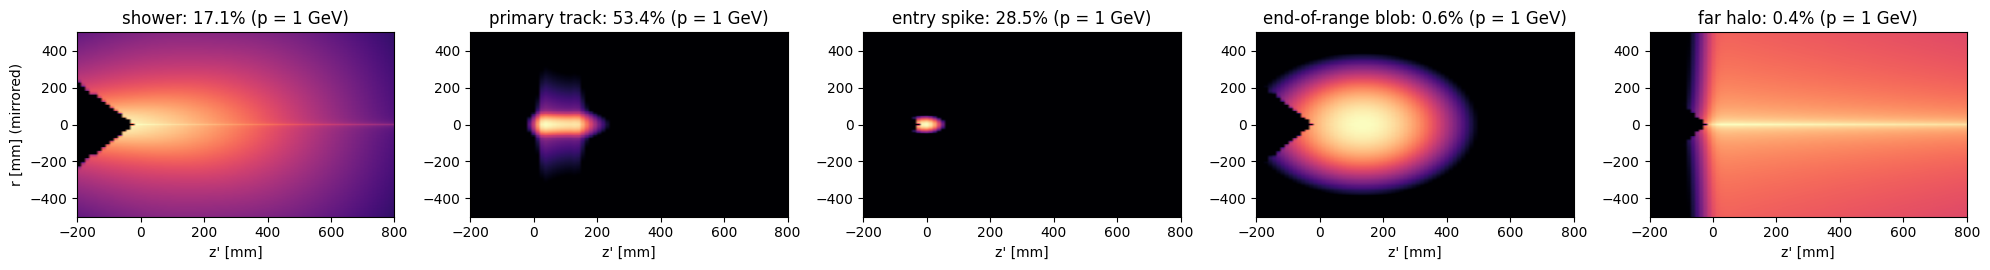

In [16]:
P_SHOW = (0.8, 2.0, 5.0, 15.0)
with torch.no_grad():
    lnp_s = torch.log(torch.tensor(P_SHOW, device=DEVICE))
    dens = (SHAPE(lnp_s) - LOG_VOL).exp().cpu().numpy()
zc_np, rc_np = ZC.cpu().numpy(), RC.cpu().numpy()
xs = np.linspace(-500, 500, 201)
fig, axes = plt.subplots(2, 4, figsize=(17, 6.2))
TH = 0.45
for j, p in enumerate(P_SHOW):
    lin = np.stack([np.interp(np.abs(xs), rc_np, row) for row in dens[j]], 1)
    img = np.where(lin > 1e-25, np.log10(np.clip(lin, 1e-14, None)), np.nan)
    vmax = np.nanmax(img)
    axes[0, j].imshow(img, origin="lower", aspect="auto", extent=[Z_MIN, Z_MAX, -500, 500], cmap="magma", vmin=vmax - 5, vmax=vmax)
    axes[0, j].set_facecolor("0.85")
    axes[0, j].set_title(f"new formula, p = {p:g} GeV: body of revolution", fontsize=9)
    Zg, Xg = np.meshgrid(zc_np, xs, indexing="ij")
    cut = (Zg * np.cos(TH) - Xg * np.sin(TH)) >= 0
    axes[1, j].imshow(np.where(cut.T, img, np.nan), origin="lower", aspect="auto", extent=[Z_MIN, Z_MAX, -500, 500], cmap="magma",
                      vmin=vmax - 5, vmax=vmax)
    axes[1, j].set_facecolor("0.85"); axes[1, j].set_title(f"cut by the front face (θ = {TH})", fontsize=9)
    for a_ in axes[:, j]:
        a_.set_xlabel("z' [mm]"); a_.set_xlim(-200, 1300)
axes[0, 0].set_ylabel("r [mm] (mirrored)"); axes[1, 0].set_ylabel("x' [mm]")
plt.tight_layout(); plt.show()

with torch.no_grad():
    lw, comp, _ = NEW["slab"].components(torch.log(torch.tensor([1.0], device=DEVICE)))
    obs = OBS_MASK.float()
    wv = [float(x.exp()) * float((c_[0].exp() * obs).sum()) for x, c_ in zip(lw, comp)]
fig, axes = plt.subplots(1, len(comp), figsize=(4 * len(comp), 2.8))
for a_, c_, t_, w_ in zip(axes, comp, COMP_NAMES, wv):
    d = ((c_[0].exp() * obs) / (c_[0].exp() * obs).sum() / LOG_VOL.exp()).cpu().numpy()
    img = np.log10(np.clip(np.stack([np.interp(np.abs(xs), rc_np, row) for row in d], 1), 1e-14, None))
    a_.imshow(img, origin="lower", aspect="auto", extent=[Z_MIN, Z_MAX, -500, 500], cmap="magma", vmin=img.max() - 5, vmax=img.max())
    a_.set(title=f"{t_}: {w_ / sum(wv):.1%} (p = 1 GeV)", xlabel="z' [mm]", xlim=(-200, 800))
axes[0].set_ylabel("r [mm] (mirrored)")
plt.tight_layout(); plt.show()

The 95 %-energy bodies of the mean shower (`bodies_3d` of 00), new formula vs the report's GFlash and MLP:

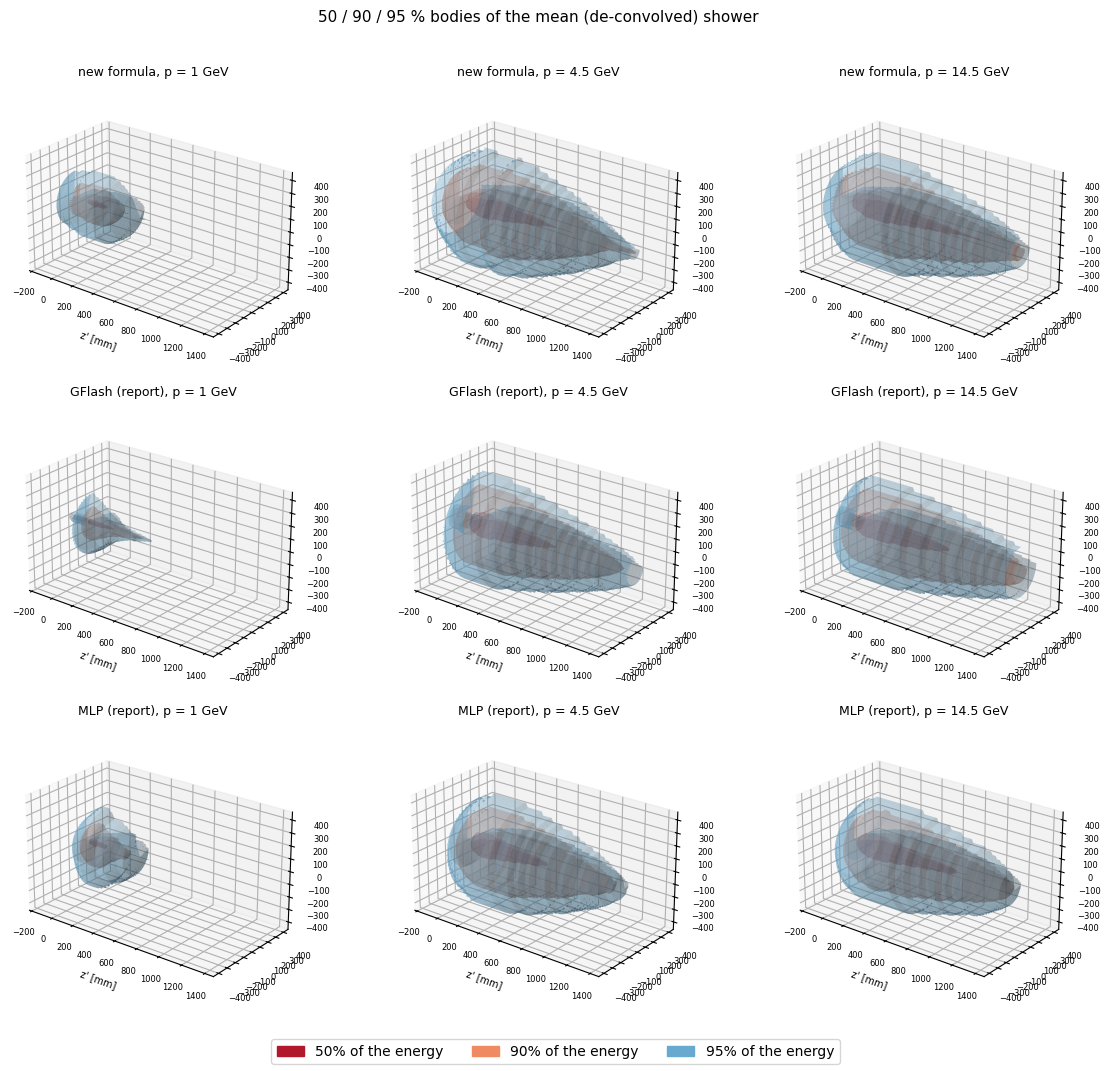

In [17]:
bodies_3d({"new formula": SHAPE, "GFlash (report)": REPORT["gflash_n6"], "MLP (report)": REPORT["mlp"]},
          p_values=(1.0, 4.5, 14.5), fractions=(0.5, 0.9, 0.95), title="50 / 90 / 95 % bodies of the mean (de-convolved) shower")

## 7. Shapes in the sense of the report (Table 2): mean-shower regions and envelope bodies

The report compares two kinds of 3D shapes, per 1 GeV bin:

- **r95**: the smallest region of a model's mean map that holds 95 % of the energy (`iso_radius`), with the report's volume
  $V = \sum \pi r_{95}(z')^2 \Delta z'$ and coverage $c$ = fraction of test showers with ≥ 95 % of their energy inside;
- **98 % bodies**: the smallest body of revolution holding ≥ 95 % of the energy in 98 % of the showers (envelope 02, drop 03).

`scripts/particle_shapes.py` recomputes the report's shapes (they reproduce its Table 2) and adds: the r95 region of the new formula,
the drop refitted with a multi-start search, the **super-egg** (two half super-ellipsoids $r = A(1-|\tau|^n)^{1/m}$ with different
front and back lengths), the **calibrated iso-density body** of the new formula (the report's recommended next step), the bodies
**smoothed in $\ln p$** and validated per bin (the report's limitation 3), the volume inside the data domain and **inside the detector
slab** (the part in front of the tilted entrance face never holds a deposit), and the mean energy fraction inside ($E_{in}$; an r95
region should hold 0.95 of the actual energy).

In [18]:
SH = pd.DataFrame(json.load(open(f"{FINAL}/shapes.json"))["shapes"]).set_index("shape")
ORDER = ["r95 baseline (report)", "r95 MLP (report)", "r95 MLP-formula (report)", "r95 new formula", "98% envelope (report)",
         "98% drop (report)", "98% drop (refit)", "98% drop (smoothed in ln p)", "98% superegg (refit)", "98% superegg (smoothed in ln p)",
         "98% iso-density (new formula)"]
tab = SH.loc[[o for o in ORDER if o in SH.index], ["V", "V_in", "V_slab", "cov", "cov_min", "E_in"]]
tab.columns = ["V (report def.) [L]", "V in data domain [L]", "V in detector slab [L]", "coverage", "min coverage (bin)", "E_in"]
display(tab.round(3))
e1 = pd.read_csv("lanes/E1_bodies/results/table_E95_EV98.csv").set_index("family")
print(f"non-parametric bound (ln r piecewise linear, 12 knots; lanes/E1_bodies): V in domain {e1.loc['knots12', 'V_in_L']:.0f} L, "
      f"coverage {e1.loc['knots12', 'cov_test']:.3f}")
iso90 = pd.read_csv("results/isobody/isobody_E90_EV90.csv")
for fam_ in ("knots12", "superegg", "drop"):
    print(f"criterion 90 % / 90 %: {fam_:9s} V in domain {iso90[iso90.body == fam_]['V_grid_L'].mean():6.1f} L, "
          f"slab {iso90[iso90.body == fam_]['V_slab_L'].mean():6.1f} L, coverage {iso90[iso90.body == fam_]['cov_test'].mean():.3f}")

,V (report def.) [L],V in data domain [L],V in detector slab [L],coverage,min coverage (bin),E_in
shape,,,,,,
r95 baseline (report),469.968,469.968,437.591,0.733,0.691,0.943
r95 MLP (report),465.928,465.928,441.213,0.749,0.709,0.947
r95 MLP-formula (report),439.372,439.372,409.570,0.701,0.547,0.939
r95 new formula,494.415,494.415,467.132,0.767,0.728,0.949
98% envelope (report),1965.268,1660.967,1482.988,0.976,0.960,NaN
98% drop (report),1707.318,1615.802,1469.192,0.977,0.960,NaN
98% drop (refit),1664.685,1599.883,1427.652,0.977,0.963,NaN
98% drop (smoothed in ln p),1662.358,1593.943,1422.061,0.976,0.955,NaN
98% superegg (refit),1548.172,1544.336,1394.616,0.976,0.957,NaN


non-parametric bound (ln r piecewise linear, 12 knots; lanes/E1_bodies): V in domain 1529 L, coverage 0.975
criterion 90 % / 90 %: knots12   V in domain  465.2 L, slab  444.7 L, coverage 0.888
criterion 90 % / 90 %: superegg  V in domain  468.1 L, slab  445.8 L, coverage 0.890
criterion 90 % / 90 %: drop      V in domain  478.8 L, slab  453.2 L, coverage 0.891


**What to look for.**
- **r95.** The new formula's region is close to the network's and holds 0.95 of the actual test energy ($E_{in}$). The report's
  coverage $c$ is not a quality measure of an r95 region: it counts showers, and it spreads every hit uniformly over its 48 mm cell
  while the region lives in the de-convolved space.
- **98 % bodies.** The report's drop is close to optimal: the super-egg is ≈ 3.5 % smaller inside the data domain and the
  non-parametric bound ≈ 4.4 %. Every good body fills most of the domain ($r_{max} \approx$ 650–700 mm against the cut $r < 700$ mm):
  the 2 % most extreme showers decide (a hadron shower holds 95 % of its energy within ≈ 1 $\lambda_I$ only on average). With
  90 % / 90 % the volumes fall by a factor ≈ 3 and the ranking is the same.
- **Calibrated iso-density** (the report's recommendation) is not smaller than the drop: the criterion is set by atypical showers,
  not by the mean shape.
- **Smoothing in ln p**: the drop's parameters can be smoothed (coverage stays ≥ 0.955 in every bin); the six-parameter super-egg
  loses coverage in some bins.
- **Inside the detector slab** every body occupies 8–11 % less volume.

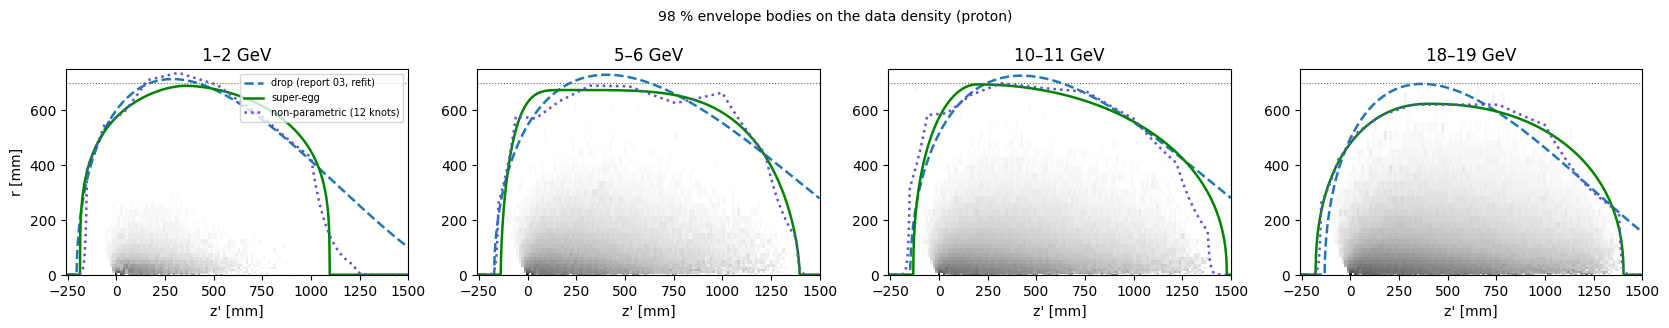

In [19]:
import importlib.util
spec = importlib.util.spec_from_file_location("e1fam", "lanes/E1_bodies/fam.py")
e1fam = importlib.util.module_from_spec(spec); spec.loader.exec_module(e1fam)
E1REG = e1fam.registry()


def body_fit(path):
    d = json.load(open(path))
    return d["x"], d["A"]


def env_figure(bins_show=(1, 5, 10, 18), r_show=750):
    vol = np.exp(LOG_VOL.cpu().numpy()); ze_ = Z_EDGES.cpu().numpy(); re_ = R_EDGES.cpu().numpy()
    h = data["train"].hits()
    zz = np.linspace(-260, 1500, 1200)
    fig, axes = plt.subplots(1, len(bins_show), figsize=(4.2 * len(bins_show), 3.3))
    for ax, b in zip(axes, bins_show):
        m = (h.p >= b) & (h.p < b + 1)
        H, _, _ = np.histogram2d(h.z[m], h.r[m], bins=[ze_, re_], weights=h.w[m])
        d = H / max(h.ev[m].nunique(), 1) / vol
        ax.pcolormesh(ze_, re_, np.log10(np.clip(d.T, 1e-14, None)), cmap="Greys", vmin=np.log10(d.max()) - 6, vmax=np.log10(d.max()))
        for key, path, col, ls, lab in (("drop", f"{FINAL}/bodies_E95_EV98/drop_bin{b:02d}.json", "#1f77b4", "--", "drop (report 03, refit)"),
                                        ("superegg", f"{FINAL}/bodies_E95_EV98/superegg_bin{b:02d}.json", "#008300", "-", "super-egg"),
                                        ("knots12", f"lanes/E1_bodies/results/fits/E95_EV98/knots12/bin{b:02d}.json", "#6250d6", ":", "non-parametric (12 knots)")):
            if os.path.exists(path):
                x, A = body_fit(path)
                ax.plot(zz, E1REG[key][0].radius(zz, x, A), ls, color=col, lw=1.8, label=lab)
        ax.axhline(700, color="0.4", lw=0.8, ls=":"); ax.set(xlim=(-260, 1500), ylim=(0, r_show), xlabel="z' [mm]", title=f"{b}–{b + 1} GeV")
    axes[0].set_ylabel("r [mm]"); axes[0].legend(fontsize=7, loc="upper right")
    fig.suptitle("98 % envelope bodies on the data density (proton)", fontsize=10)
    plt.tight_layout(); plt.show()


env_figure()

## 8. Independent check on a second simulation sample

The components, the lateral form and the degree were chosen on the validation set. Test values were logged during the exploration
as well, but an independent review (`review/R2_numbers`) found that every choice agrees with the validation ranking. As a fully
independent check the models are evaluated on the **second proton sample** of the same simulation (`..._balanced_s2_v3.csv`,
another random seed: 99 948 events that none of the models has seen). Loading it from the CSV takes ≈ 7 minutes; the compact
tensors are cached in `cache/proton_s2_sets.pt`.

In [20]:
S2 = "cache/proton_s2_sets.pt"
if os.path.exists(S2):
    ck2 = torch.load(S2, weights_only=False)
    s2 = {k: Showers(v["ev"], v["off"], v["xyz"], v["w"], v["box"]) for k, v in ck2["sets"].items()}

    def nll_s2(model, fn):
        return np.concatenate([fn(model, sh.to(DEVICE)) for sh in s2.values()])

    for name, _, ms, m3d in TABLE[:6]:
        for metric, m, fn in (("std", ms, test_nll), ("3D", m3d, test_nll_slab)):
            if m is not None:
                PER[(name, metric, "s2")] = nll_s2(m, fn)
    rows = []
    for name, _, ms, m3d in TABLE[:6]:
        r = {"model": name}
        for metric in ("std", "3D"):
            if (name, metric, "s2") not in PER:
                r.update({f"{metric}: NLL (s2)": np.nan, f"{metric}: Δ vs GFlash refit (s2)": ""}); continue
            r[f"{metric}: NLL (s2)"] = PER[(name, metric, "s2")].mean()
            d, se = paired(PER[(name, metric, "s2")], PER[(BASE[metric], metric, "s2")])
            r[f"{metric}: Δ vs GFlash refit (s2)"] = f"{d:+.4f} ± {se:.4f}"
        rows.append(r)
    S2TAB = pd.DataFrame(rows).set_index("model")
    print(f"s2 sample: {sum(len(v) for v in s2.values())} events")
    display(S2TAB.style.format({c: "{:.4f}" for c in S2TAB.columns if "NLL" in c}, na_rep="–"))
    S2TAB.to_csv(f"{FINAL}/notebook_accuracy_s2.csv")
else:
    print("second sample not cached – run scripts/build_cache_s2.py once (≈ 7 min)")

s2 sample: 99948 events


,std: NLL (s2),std: Δ vs GFlash refit (s2),3D: NLL (s2),3D: Δ vs GFlash refit (s2)
model,,,,
GFlash n=6 (report),18.2437,+0.0199 ± 0.0003,–,
"GFlash (× Ā / 3D refit, n = 6 / 6)",18.2238,+0.0000 ± 0.0000,18.1917,+0.0000 ± 0.0000
"NEW, compact (n = 2)",18.1839,-0.0399 ± 0.0007,18.1568,-0.0348 ± 0.0006
NEW (1-SE),18.1829,-0.0409 ± 0.0007,18.1553,-0.0363 ± 0.0006
MLP L3xH16 (report),18.1814,-0.0424 ± 0.0007,–,
MLP L3xH16 (fine-tuned),18.1790,-0.0449 ± 0.0007,18.1509,-0.0407 ± 0.0007


## 9. Summary

The numbers below are printed from this run (test set, like with like).

In [21]:
def tt(name, metric):
    return PER[(name, metric, "test")].mean()


lines = [
    f"* Report metric: GFlash (report) {tt('GFlash n=6 (report)', 'std'):.4f} (45 par.) → GFlash × Ā refit {tt(BASE['std'], 'std'):.4f} (45, fixed geometric template)"
    f" → new formula × Ā {tt('NEW (1-SE)', 'std'):.4f} ({NEW['std'].n_params()} par.; compact {tt('NEW, compact (n = 2)', 'std'):.4f} with"
    f" {LADDER[('std', 2)].n_params()}) → MLP {tt(MLPN, 'std'):.4f} (881).",
    f"* 3D metric: GFlash refit {tt(BASE['3D'], '3D'):.4f} → new formula {tt('NEW (1-SE)', '3D'):.4f} (compact {tt('NEW, compact (n = 2)', '3D'):.4f})"
    f" → MLP trained in 3D {tt(MLPN, '3D'):.4f}.",
]
for metric, label in (("std", "report metric"), ("3D", "3D metric")):
    g, n6, mlp = tt(BASE[metric], metric), tt("NEW (1-SE)", metric), tt(MLPN, metric)
    lines.append(f"* {label}: the new formula closes {(g - n6) / (g - mlp):.0%} of the gap between the GFlash formula and the MLP trained the same way.")
display(Markdown("\n".join(lines)))

* Report metric: GFlash (report) 18.2536 (45 par.) → GFlash × Ā refit 18.2331 (45, fixed geometric template) → new formula × Ā 18.1940 (143 par.; compact 18.1952 with 87) → MLP 18.1898 (881).
* 3D metric: GFlash refit 18.2003 → new formula 18.1660 (compact 18.1676) → MLP trained in 3D 18.1614.
* report metric: the new formula closes 90% of the gap between the GFlash formula and the MLP trained the same way.
* 3D metric: the new formula closes 88% of the gap between the GFlash formula and the MLP trained the same way.

1. **Geometry.** In this detector the proton shower is a body of revolution **cut by the tilted entrance face** (and the back face):
   the origin of the shower frame is the first hit layer, so every hit satisfies $z'\cos\theta - x'\sin\theta \ge 0$. The networks of
   05/06 learned the cut as a cone; a product $L(z')\,T(r)$ cannot. In the report's metric the fixed template $\bar A$ (the cut averaged
   over the incidence angles) improves the GFlash formula by ≈ 0.020 nat without new parameters; about half of that comes from the
   report metric counting mass where no hit can be recorded (with a normalisation over the instrumented cells the gain is ≈ 0.010,
   `review/R1_likelihood`).
2. **A better closed form for the proton**: shower (plateau depth profile × [Gauss core + Cauchy body + exponential-$dE/dr$ halo])
   + primary track (attenuated until the first nuclear interaction, ending at the range $R(T)$, widening with depth by multiple
   scattering) + entry spike + end-of-range blob + diffuse far halo. Against GFlash refitted the same way it is better at every
   momentum, most below 2 GeV (stopping protons); overall by ≈ 0.03–0.04 nat, already with the degree-2 version. It closes about
   90 % of the gap to the network trained the same way (printed above), with a sixth of its parameters; the network is still slightly
   better above 2 GeV. The literature's Bock two-gamma profile is not better. The ranking and the sizes replicate on a second,
   independent simulation sample (≈ 100 000 events).
3. **Envelope bodies.** For the "smallest body holding 95 % of the energy in 98 % of the showers" the report's drop is within ≈ 4 % of
   the best possible body of revolution; the best closed form (super-egg) gains ≈ 3.5 %. The volume is set by the criterion and the
   data domain, not by the shape family; the volume the body really occupies in the detector (inside the slab) is 8–11 % smaller.
   The calibrated iso-density body recommended by the report is not smaller than the drop.

**Caveats.**
(1) Neither likelihood is normalised exactly over the instrumented cells: ≈ 0.22–0.27 nat of every model's mass lies where no hit can
be recorded (outer edge, beam hole, module gaps). Comparisons are therefore made only between models trained under the same
likelihood; the independent review found the remaining bias of such paired differences ≤ 0.001 nat in the 3D metric.
(2) The network reference is the report's MLP fine-tuned with the same optimiser as the formulas (it improves the report's MLP by
≈ 0.002 nat); a larger network could still be somewhat better.
(3) The 1-SE rule picks the top rung of nested, warm-started ladders (as for GFlash in 01); the degree-2 version (87 parameters) is
within ≈ 0.0015 nat of it and is the better choice when interpretability matters.
(4) The cross-section is normalised over the grid's disc at every depth. Normalised over the infinite plane, the fit is 0.001–0.002
nat better, but a very wide halo then acts as a depth-dependent sink of energy with scales of tens of metres; we prefer the physical
version.
(5) The track parameters describe the mean energy profile effectively (the track end is shorter than the CSDA range, because protons
that interact before stopping are averaged in); below ≈ 0.6 GeV the component split is effective as well, and above 2 GeV the
track's halo also takes part of the hadronic core (for the proton the multiple-scattering term is effective, unlike for the muon).
(6) The origin of the shower frame is defined from all hits, including the late (> 100 ns) ones that the likelihood drops; in 1.2 % of
the events the first recorded layer lies behind the origin layer. This is inherited from the report and affects all models alike.